/var/folders/s2/_qxs1d_57r18ktd8jtkpm0sw0000gn/T/ipykernel_45512/2306841750.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=arr_df, x='Model', y='arrival_hz', ax=axes[1, 0], palette="Set2")


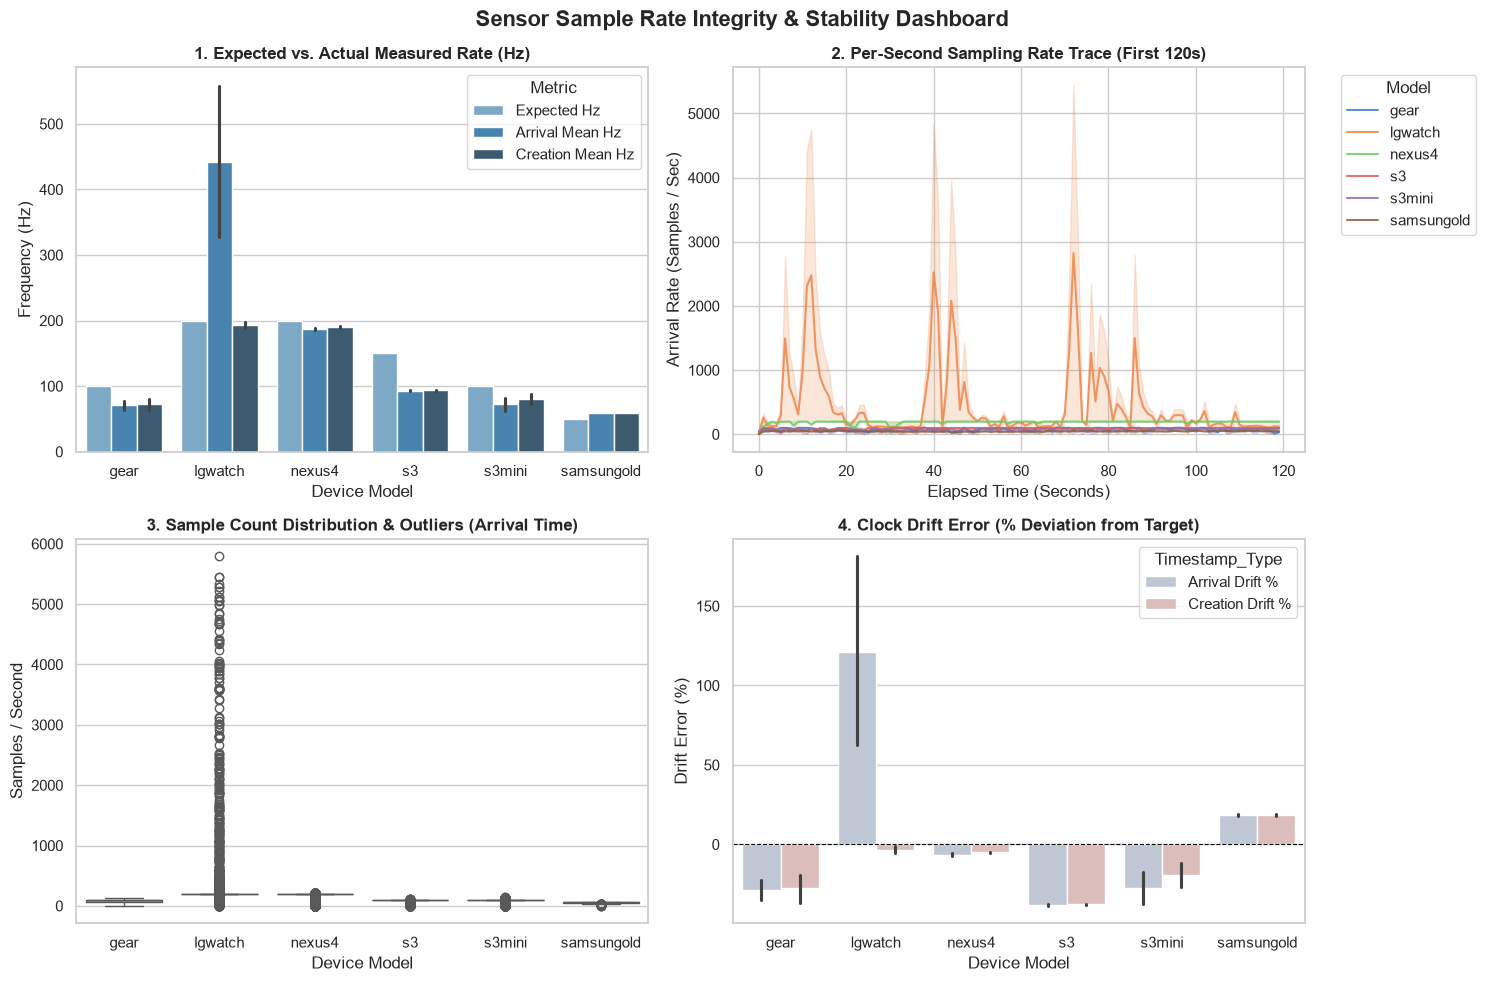

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid", palette="muted")

# 1. Load the result CSVs
report_df = pd.read_csv("sample_rate_integrity_report.csv")
arr_df = pd.read_csv("sample_counts_per_second_arrival.csv")
cre_df = pd.read_csv("sample_counts_per_second_creation.csv")

# Initialize 2x2 subplot dashboard
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle("Sensor Sample Rate Integrity & Stability Dashboard", fontsize=16, fontweight="bold")

# ----------------------------------------------------
# Plot 1: Expected vs. Actual Measured Frequency (Hz)
# ----------------------------------------------------
df_melted_rates = pd.melt(
    report_df, 
    id_vars=['Model'], 
    value_vars=['expected_hz', 'arr_mean', 'cre_mean'],
    var_name='Metric', 
    value_name='Hz'
)
# Rename metric labels for clean legend
df_melted_rates['Metric'] = df_melted_rates['Metric'].map({
    'expected_hz': 'Expected Hz',
    'arr_mean': 'Arrival Mean Hz',
    'cre_mean': 'Creation Mean Hz'
})

sns.barplot(data=df_melted_rates, x='Model', y='Hz', hue='Metric', ax=axes[0, 0], palette="Blues_d")
axes[0, 0].set_title("1. Expected vs. Actual Measured Rate (Hz)", fontweight="bold")
axes[0, 0].set_ylabel("Frequency (Hz)")
axes[0, 0].set_xlabel("Device Model")

# ----------------------------------------------------
# Plot 2: Time-Series Sample Stability (Jitter over Time)
# ----------------------------------------------------
# Select first user/device per model for clean line plotting
arr_df['Arrival_Sec'] = pd.to_datetime(arr_df['Arrival_Sec'])
arr_df['Elapsed_Sec'] = arr_df.groupby(['Model', 'Device']).cumcount()

# Plot line trace for up to 120 seconds per model
sns.lineplot(
    data=arr_df[arr_df['Elapsed_Sec'] < 120], 
    x='Elapsed_Sec', 
    y='arrival_hz', 
    hue='Model', 
    ax=axes[0, 1], 
    alpha=0.85
)
axes[0, 1].set_title("2. Per-Second Sampling Rate Trace (First 120s)", fontweight="bold")
axes[0, 1].set_xlabel("Elapsed Time (Seconds)")
axes[0, 1].set_ylabel("Arrival Rate (Samples / Sec)")
axes[0, 1].legend(title="Model", bbox_to_anchor=(1.05, 1), loc='upper left')

# ----------------------------------------------------
# Plot 3: Distribution & Outlier Detection (Boxplot)
# ----------------------------------------------------
sns.boxplot(data=arr_df, x='Model', y='arrival_hz', ax=axes[1, 0], palette="Set2")
axes[1, 0].set_title("3. Sample Count Distribution & Outliers (Arrival Time)", fontweight="bold")
axes[1, 0].set_ylabel("Samples / Second")
axes[1, 0].set_xlabel("Device Model")

# ----------------------------------------------------
# Plot 4: Clock Drift Percentage (% Deviation)
# ----------------------------------------------------
df_melted_drift = pd.melt(
    report_df, 
    id_vars=['Model'], 
    value_vars=['arr_drift_%', 'cre_drift_%'],
    var_name='Timestamp_Type', 
    value_name='Drift_%'
)
df_melted_drift['Timestamp_Type'] = df_melted_drift['Timestamp_Type'].map({
    'arr_drift_%': 'Arrival Drift %',
    'cre_drift_%': 'Creation Drift %'
})

sns.barplot(data=df_melted_drift, x='Model', y='Drift_%', hue='Timestamp_Type', ax=axes[1, 1], palette="vlag")
axes[1, 1].axhline(0, color='black', linestyle='--', linewidth=0.8)
axes[1, 1].set_title("4. Clock Drift Error (% Deviation from Target)", fontweight="bold")
axes[1, 1].set_ylabel("Drift Error (%)")
axes[1, 1].set_xlabel("Device Model")

plt.tight_layout()
plt.savefig("sample_rate_diagnostics.png", dpi=300, bbox_inches='tight')
plt.show()